# LAPORAN PRAKTIKUM DATA MINING
## Evaluasi Model Klasifikasi: Confusion Matrix, Accuracy, Precision, Recall, dan F1-Score

**Universitas Negeri Padang — Fakultas Teknik**  
**Departemen Teknik Elektronika — Program Studi Informatika**  
**Tahun 2026**

Sumber utama: *Modul Praktikum Data Mining — Evaluasi Model Klasifikasi*, Dr. Yeka Hendriyani, S.Kom., M.Kom. (2026), seluruh 6 halaman.

Notebook ini mencakup Bagian 4.1–4.8, Tugas 1–4, serta sistematika laporan pada Bagian 6. Data sepenuhnya sintetis; kelas positif adalah **fraud (1)** dan kelas negatif **normal (0)**.

### Cara menjalankan
1. Buka notebook di Jupyter Notebook, VS Code, atau Google Colab dengan Python 3.10+.
2. Isi identitas pada sel berikut, lalu pilih **Restart Kernel and Run All** (Colab: **Runtime → Run all**).
3. Sel penyiapan hanya mengunduh paket bila belum terpasang; lingkungan yang sudah lengkap dapat menjalankan notebook tanpa internet.
4. Tabel CSV dan gambar disimpan otomatis ke folder `hasil_evaluasi`. Output yang disertakan merupakan hasil eksekusi nyata, dan dapat diperbarui dengan menjalankan ulang notebook.

**Ketentuan pengumpulan dari modul:** laporan akhir dikumpulkan sebagai PDF melalui SMILE UNP sesuai tenggat kelas, dengan nama `NIM_Nama_PraktikumEvaluasiModel.pdf`. Notebook ini adalah program dan bahan laporan; isi identitas serta periksa tata letak sebelum mengekspor ke PDF menggunakan fasilitas cetak/ekspor lingkungan notebook.

In [1]:

from datetime import date
from IPython.display import display, Markdown

# Data anggota kelompok
ANGGOTA = [
    {"nama": "Muhammad Zahran", "nim": "24343077"},
    {"nama": "Auditya Merosya Putri", "nim": "24343001"},
    {"nama": "Muhammad Riyad Anwari", "nim": "24343044"}
]

KELAS = "Data Mining"
TANGGAL = "2026-11-19"

# Menampilkan identitas seluruh anggota
output = ""

for i, anggota in enumerate(ANGGOTA, start=1):
    output += f"**Anggota {i}:** {anggota['nama']}  \n"
    output += f"**NIM:** {anggota['nim']}  \n\n"

output += f"**Kelas:** {KELAS}  \n"
output += f"**Tanggal:** {TANGGAL}"

display(Markdown(output))


**Nama:** Muhammad Riyad Anwari  
**NIM:** 24343044  
**Kelas:** Data Mining  
**Tanggal:** 2026-11-19

# BAB I — Pendahuluan

### 1.1 Tujuan
- Mengidentifikasi TP, TN, FP, dan FN dalam klasifikasi biner.
- Menghitung accuracy, precision, recall, dan F1-score secara manual serta memverifikasinya dengan scikit-learn.
- Melatih Decision Tree, menampilkan confusion matrix, dan menginterpretasikan kesalahan prediksi.
- Menjelaskan keterbatasan accuracy pada kelas tidak seimbang dan pengaruh threshold terhadap deteksi fraud.

### 1.2 Konteks dan dataset
Deteksi fraud menghadapi dua jenis kesalahan: transaksi normal salah ditandai fraud (FP), dan transaksi fraud lolos (FN). Pemilihan metrik harus mempertimbangkan konsekuensi keduanya.

Dataset terdiri dari **500 transaksi sintetis** dengan generator `np.random.default_rng(42)`, sesuai kode modul, tanpa data eksternal.

| Kolom | Arti | Jenis/nilai |
|---|---|---|
| `amount` | Nominal transaksi dalam satuan simulasi | Numerik, lognormal, dibulatkan 2 desimal |
| `hour` | Jam transaksi | 0–23 |
| `new_device` | Indikator perangkat baru | 0/1 |
| `foreign_ip` | Indikator IP luar negeri | 0/1 |
| `isFraud` | Target | 0 = normal, 1 = fraud |

Data dibagi 70% latih dan 30% uji secara terstratifikasi. Data uji tidak digunakan untuk melatih model. Parameter pembangkitan, pembagian data, dan model dipertahankan persis seperti modul.

### 1.3 Dasar evaluasi
Dengan `labels=[0, 1]`, scikit-learn menyusun confusion matrix sebagai **`[[TN, FP], [FN, TP]]`**: baris menunjukkan aktual dan kolom menunjukkan prediksi. Tabel teori modul yang mendahulukan kelas fraud memiliki urutan berbeda; label selalu ditampilkan untuk mencegah tertukar.

$$Accuracy=\frac{TP+TN}{TP+TN+FP+FN},\quad Precision=\frac{TP}{TP+FP}$$
$$Recall=\frac{TP}{TP+FN},\quad F1=\frac{2\,Precision\,Recall}{Precision+Recall}$$

Jika penyebut nol, nilai dikembalikan sebagai 0 secara eksplisit, konsisten dengan `zero_division=0`.

# BAB II — Langkah Pengerjaan
### 2.1 Penyiapan lingkungan
Paket yang digunakan: NumPy, pandas, scikit-learn, matplotlib, dan IPython. Versi aktual dicatat agar hasil dapat ditelusuri. Perbedaan versi pustaka dapat memengaruhi hasil; kesimpulan di bawah dihitung dari output yang sedang dijalankan.

In [2]:
import sys
import importlib.util
import subprocess

paket = {"numpy": "numpy", "pandas": "pandas", "sklearn": "scikit-learn",
         "matplotlib": "matplotlib", "IPython": "ipython"}
belum_ada = [nama for modul, nama in paket.items() if importlib.util.find_spec(modul) is None]
if belum_ada:
    subprocess.check_call([sys.executable, "-m", "pip", "install", *belum_ada])

import platform
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn
from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay, accuracy_score,
                             precision_score, recall_score, f1_score, classification_report)

OUT = Path("hasil_evaluasi")
OUT.mkdir(exist_ok=True)
versi = {"Python": platform.python_version(), "numpy": np.__version__,
         "pandas": pd.__version__, "scikit-learn": sklearn.__version__,
         "matplotlib": matplotlib.__version__}
display(pd.Series(versi, name="Versi").to_frame())
pd.Series(versi, name="Versi").to_csv(OUT / "versi_lingkungan.csv")

,Versi
Python,3.13.9
numpy,2.3.5
pandas,2.3.3
scikit-learn,1.9.1
matplotlib,3.11.2


### 2.2 Bagian 4.1 — Menyiapkan dataset sintetis
Label dibangkitkan secara probabilistik dari skor dalam modul. Semua baris dipertahankan; tidak dilakukan penyeimbangan ulang maupun perubahan rumus pembangkitan.

In [3]:
rng = np.random.default_rng(42)
n = 500
amount = rng.lognormal(mean=5.0, sigma=1.0, size=n)
hour = rng.integers(0, 24, n)
new_device = rng.binomial(1, 0.25, n)
foreign_ip = rng.binomial(1, 0.12, n)
score = -4.5 + 0.45*(amount > 300) + 1.1*new_device + 1.5*foreign_ip + 0.7*(hour < 5)
prob = 1/(1+np.exp(-score))
isFraud = rng.binomial(1, prob)
df = pd.DataFrame({'amount': amount.round(2), 'hour': hour,
                   'new_device': new_device, 'foreign_ip': foreign_ip,
                   'isFraud': isFraud})
display(df.head())
distribusi = df['isFraud'].value_counts().reindex([0, 1], fill_value=0).rename('jumlah').to_frame()
distribusi.index.name = 'isFraud'
distribusi['persentase'] = distribusi['jumlah'] / len(df) * 100
print('Distribusi kelas:')
display(distribusi)
assert df.shape == (500, 5) and not df.isna().any().any()
assert set(df['isFraud']) == {0, 1}
assert df['hour'].between(0, 23).all()
df.to_csv(OUT / 'dataset_transaksi_sintetis.csv', index=False)
display(Markdown(f"Proporsi fraud = **{df['isFraud'].mean():.2%}**; kelas normal = **{1-df['isFraud'].mean():.2%}**. Distribusi ini menunjukkan ketidakseimbangan kelas."))

,amount,hour,new_device,foreign_ip,isFraud
0,201.28,9,0,0,0
1,52.46,8,0,0,0
2,314.33,17,1,0,0
3,380.15,3,0,0,0
4,21.09,5,1,0,0


Distribusi kelas:


,jumlah,persentase
isFraud,,
0,484,96.8
1,16,3.2


Proporsi fraud = **3.20%**; kelas normal = **96.80%**. Distribusi ini menunjukkan ketidakseimbangan kelas.

### 2.3 Bagian 4.2 — Membagi data dan melatih model
`stratify=y` menjaga proporsi kelas mendekati distribusi asal. `class_weight='balanced'` meningkatkan bobot kelas minoritas saat pelatihan, tetapi tidak menjamin recall atau precision tinggi. Fitur target dikeluarkan dari `X` untuk mencegah kebocoran label.

In [4]:
X = df.drop(columns='isFraud')
y = df['isFraud']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y)
model = DecisionTreeClassifier(max_depth=4, class_weight='balanced', random_state=42)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
print('Data uji:', len(y_test))
ringkasan_split = pd.DataFrame([
    {'Bagian': nama, 'Jumlah': len(label), 'Normal': int((label == 0).sum()),
     'Fraud': int((label == 1).sum()), 'Proporsi fraud': label.mean()}
    for nama, label in [('Latih', y_train), ('Uji', y_test)]
])
display(ringkasan_split)
assert len(y_test) == 150 and len(y_train) == 350
assert set(X_train.index).isdisjoint(X_test.index)

Data uji: 150


,Bagian,Jumlah,Normal,Fraud,Proporsi fraud
0,Latih,350,339,11,0.031429
1,Uji,150,145,5,0.033333


### 2.4 Bagian 4.3 — Confusion matrix aktual

In [5]:
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
tn, fp, fn, tp = cm.ravel()
print('Confusion matrix:\n', cm)
print(f'TP={tp}, TN={tn}, FP={fp}, FN={fn}')
cm_tabel = pd.DataFrame(cm, index=['Aktual Normal (0)', 'Aktual Fraud (1)'],
                        columns=['Prediksi Normal (0)', 'Prediksi Fraud (1)'])
display(cm_tabel)
assert cm.sum() == len(y_test)
cm_tabel.to_csv(OUT / 'confusion_matrix_decision_tree.csv')

Confusion matrix:
 [[113  32]
 [  3   2]]
TP=2, TN=113, FP=32, FN=3


,Prediksi Normal (0),Prediksi Fraud (1)
Aktual Normal (0),113,32
Aktual Fraud (1),3,2


### 2.5 Bagian 4.4 — Perhitungan manual dan verifikasi
Empat metrik berikut dihitung langsung dari TP/TN/FP/FN aktual, bukan dari angka contoh pada teori. Pemeriksaan numerik menggunakan nilai penuh, bukan tampilan yang dibulatkan.

In [6]:
accuracy = (tp + tn) / (tp + tn + fp + fn)
precision = tp / (tp + fp) if tp + fp else 0
recall = tp / (tp + fn) if tp + fn else 0
f1 = 2*precision*recall/(precision+recall) if precision+recall else 0
manual = np.array([accuracy, precision, recall, f1])
otomatis = np.array([accuracy_score(y_test, y_pred),
                     precision_score(y_test, y_pred, pos_label=1, zero_division=0),
                     recall_score(y_test, y_pred, pos_label=1, zero_division=0),
                     f1_score(y_test, y_pred, pos_label=1, zero_division=0)])
verifikasi = pd.DataFrame({'Metrik': ['Accuracy', 'Precision fraud', 'Recall fraud', 'F1 fraud'],
                          'Manual': manual, 'scikit-learn': otomatis,
                          'Selisih absolut': np.abs(manual-otomatis)})
display(verifikasi.round(6))
np.testing.assert_allclose(manual, otomatis, rtol=0, atol=1e-12)
print(f'Accuracy={accuracy:.3f}; Precision={precision:.3f}; Recall={recall:.3f}; F1={f1:.3f}')
print('Verifikasi lulus: seluruh metrik manual sama dengan scikit-learn dalam toleransi 1e-12.')
display(Markdown(f"""
- Accuracy = ({tp} + {tn}) / {cm.sum()} = **{accuracy:.4f} ({accuracy:.2%})**.
- Precision = {tp} / ({tp} + {fp}) = **{precision:.4f} ({precision:.2%})**.
- Recall = {tp} / ({tp} + {fn}) = **{recall:.4f} ({recall:.2%})**.
- F1 = 2 × precision × recall / (precision + recall) = **{f1:.4f} ({f1:.2%})**.
"""))
verifikasi.to_csv(OUT / 'verifikasi_metrik.csv', index=False)

,Metrik,Manual,scikit-learn,Selisih absolut
0,Accuracy,0.766667,0.766667,0.0
1,Precision fraud,0.058824,0.058824,0.0
2,Recall fraud,0.400000,0.400000,0.0
3,F1 fraud,0.102564,0.102564,0.0


Accuracy=0.767; Precision=0.059; Recall=0.400; F1=0.103
Verifikasi lulus: seluruh metrik manual sama dengan scikit-learn dalam toleransi 1e-12.



- Accuracy = (2 + 113) / 150 = **0.7667 (76.67%)**.
- Precision = 2 / (2 + 32) = **0.0588 (5.88%)**.
- Recall = 2 / (2 + 3) = **0.4000 (40.00%)**.
- F1 = 2 × precision × recall / (precision + recall) = **0.1026 (10.26%)**.


### 2.6 Bagian 4.5 — Visualisasi confusion matrix

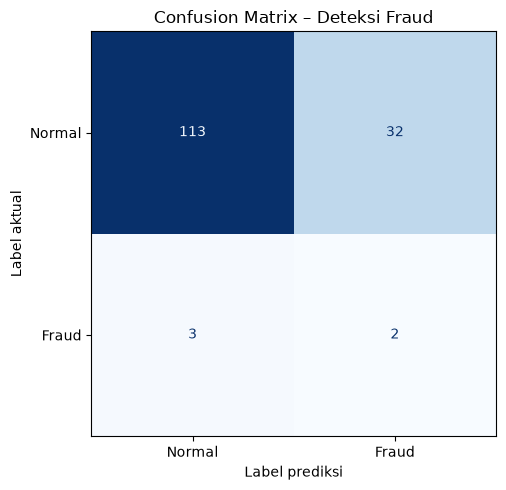

In [7]:
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Normal', 'Fraud']).plot(
    cmap='Blues', values_format='d', ax=ax, colorbar=False)
ax.set(title='Confusion Matrix – Deteksi Fraud', xlabel='Label prediksi', ylabel='Label aktual')
fig.tight_layout()
fig.savefig(OUT / 'confusion_matrix_decision_tree.png', dpi=180, bbox_inches='tight')
plt.show()

### 2.7 Bagian 4.6 — Interpretasi dan studi kasus

In [8]:
display(Markdown(f"""
Model mendeteksi **{tp}** transaksi fraud dengan benar dan mengenali **{tn}** transaksi normal dengan benar.
Terdapat **{fp} FP**, yaitu transaksi normal yang salah ditandai fraud; konsekuensinya dapat berupa verifikasi tambahan atau gangguan pada pelanggan.
Terdapat **{fn} FN**, yaitu fraud yang luput terdeteksi dan berpotensi menimbulkan kerugian.

Recall fraud sebesar **{recall:.2%}** berarti {tp} dari {tp+fn} fraud aktual berhasil ditemukan.
Precision sebesar **{precision:.2%}** berarti {tp} dari {tp+fp} alarm fraud benar.
F1 fraud sebesar **{f1:.2%}** merangkum keduanya; accuracy sebesar **{accuracy:.2%}** harus dibaca bersama metrik kelas fraud.
"""))


Model mendeteksi **2** transaksi fraud dengan benar dan mengenali **113** transaksi normal dengan benar.
Terdapat **32 FP**, yaitu transaksi normal yang salah ditandai fraud; konsekuensinya dapat berupa verifikasi tambahan atau gangguan pada pelanggan.
Terdapat **3 FN**, yaitu fraud yang luput terdeteksi dan berpotensi menimbulkan kerugian.

Recall fraud sebesar **40.00%** berarti 2 dari 5 fraud aktual berhasil ditemukan.
Precision sebesar **5.88%** berarti 2 dari 34 alarm fraud benar.
F1 fraud sebesar **10.26%** merangkum keduanya; accuracy sebesar **76.67%** harus dibaca bersama metrik kelas fraud.


### 2.8 Bagian 4.7 — Baseline semua normal
Baseline tidak dilatih dan selalu menghasilkan kelas 0. `classification_report` disajikan untuk kedua kelas. Baris **Fraud** menjadi acuan evaluasi kelas positif; weighted average dapat didominasi kelas normal.

In [9]:
baseline = np.zeros(len(y_test), dtype=int)
print('Baseline accuracy:', accuracy_score(y_test, baseline))
print('Baseline semua normal:')
print(classification_report(y_test, baseline, labels=[0, 1],
                            target_names=['Normal', 'Fraud'], zero_division=0))
print('Decision Tree:')
print(classification_report(y_test, y_pred, labels=[0, 1],
                            target_names=['Normal', 'Fraud'], zero_division=0))

def metrik_prediksi(nama, aktual, prediksi):
    a_tn, a_fp, a_fn, a_tp = confusion_matrix(aktual, prediksi, labels=[0, 1]).ravel()
    return {'Model': nama, 'Accuracy': accuracy_score(aktual, prediksi),
            'Precision fraud': precision_score(aktual, prediksi, zero_division=0),
            'Recall fraud': recall_score(aktual, prediksi, zero_division=0),
            'F1 fraud': f1_score(aktual, prediksi, zero_division=0),
            'TN': int(a_tn), 'FP': int(a_fp), 'FN': int(a_fn), 'TP': int(a_tp)}

perbandingan = pd.DataFrame([metrik_prediksi('Semua normal', y_test, baseline),
                             metrik_prediksi('Decision Tree', y_test, y_pred)])
display(perbandingan)
perbandingan.to_csv(OUT / 'perbandingan_baseline_decision_tree.csv', index=False)

Baseline accuracy: 0.9666666666666667
Baseline semua normal:
              precision    recall  f1-score   support

      Normal       0.97      1.00      0.98       145
       Fraud       0.00      0.00      0.00         5

    accuracy                           0.97       150
   macro avg       0.48      0.50      0.49       150
weighted avg       0.93      0.97      0.95       150

Decision Tree:
              precision    recall  f1-score   support

      Normal       0.97      0.78      0.87       145
       Fraud       0.06      0.40      0.10         5

    accuracy                           0.77       150
   macro avg       0.52      0.59      0.48       150
weighted avg       0.94      0.77      0.84       150



,Model,Accuracy,Precision fraud,Recall fraud,F1 fraud,TN,FP,FN,TP
0,Semua normal,0.966667,0.000000,0.0,0.000000,145,0,5,0
1,Decision Tree,0.766667,0.058824,0.4,0.102564,113,32,3,2


### 2.9 Bagian 4.8 — Pengaruh ambang prediksi
Fraud diprediksi jika probabilitas kelas 1 **≥ threshold**. Threshold yang diuji persis **0.2, 0.4, 0.5, dan 0.7**. Precision/recall dihitung untuk fraud. Output probabilitas dari pohon berbobot dipakai sesuai modul dan tidak dianggap sebagai probabilitas risiko yang sudah terkalibrasi.

,Threshold,Precision fraud,Recall fraud,F1 fraud,Accuracy,TN,FP,FN,TP
0,0.2,0.058824,0.4,0.102564,0.766667,113,32,3,2
1,0.4,0.058824,0.4,0.102564,0.766667,113,32,3,2
2,0.5,0.058824,0.4,0.102564,0.766667,113,32,3,2
3,0.7,0.055556,0.2,0.086957,0.860000,128,17,4,1


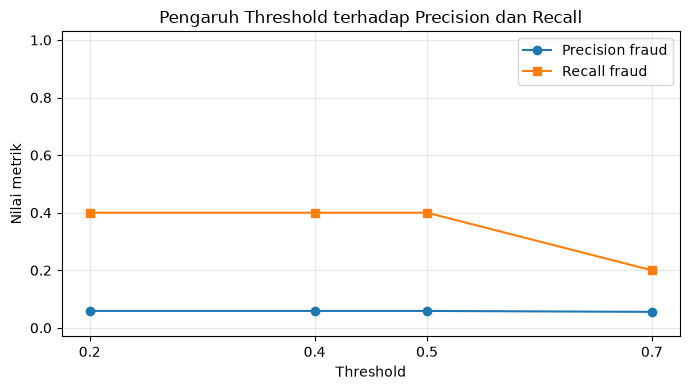

In [10]:
y_prob = model.predict_proba(X_test)[:, list(model.classes_).index(1)]
thresholds = [0.2, 0.4, 0.5, 0.7]
baris_threshold = []
for threshold in thresholds:
    pred = (y_prob >= threshold).astype(int)
    baris = metrik_prediksi(f'Threshold {threshold:.1f}', y_test, pred)
    baris['Threshold'] = threshold
    baris_threshold.append(baris)
hasil_threshold = pd.DataFrame(baris_threshold)[
    ['Threshold', 'Precision fraud', 'Recall fraud', 'F1 fraud', 'Accuracy', 'TN', 'FP', 'FN', 'TP']]
display(hasil_threshold)
hasil_threshold.to_csv(OUT / 'eksperimen_threshold.csv', index=False)

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(hasil_threshold['Threshold'], hasil_threshold['Precision fraud'], 'o-', label='Precision fraud')
ax.plot(hasil_threshold['Threshold'], hasil_threshold['Recall fraud'], 's-', label='Recall fraud')
ax.set(xlabel='Threshold', ylabel='Nilai metrik', ylim=(-0.03, 1.03),
       xticks=thresholds, title='Pengaruh Threshold terhadap Precision dan Recall')
ax.grid(alpha=0.3)
ax.legend()
fig.tight_layout()
fig.savefig(OUT / 'precision_recall_threshold.png', dpi=180, bbox_inches='tight')
plt.show()

# BAB III — Hasil Tugas
### 3.1 Tugas 1 — Hitung manual
Diketahui **TP=24, TN=156, FP=12, FN=8**, sehingga total transaksi = 200. Angka soal ini terpisah dari hasil model pada BAB II.

| Aktual / Prediksi | Normal (0) | Fraud (1) |
|---|---:|---:|
| Normal (0) | TN = 156 | FP = 12 |
| Fraud (1) | FN = 8 | TP = 24 |

- **Accuracy** = (24 + 156) / 200 = 180/200 = **0.90 = 90%**.
- **Precision** = 24 / (24 + 12) = 24/36 = **0.6667 ≈ 66.67%**.
- **Recall** = 24 / (24 + 8) = 24/32 = **0.75 = 75%**.
- **F1-score** = 2 × (2/3) × (3/4) / ((2/3) + (3/4)) = 12/17 = **0.7059 ≈ 70.59%**.

Interpretasi: 12 transaksi normal menerima alarm palsu (FP), sedangkan 8 transaksi fraud tidak terdeteksi (FN). Dari 32 fraud aktual, 24 berhasil dideteksi. Akurasi 90% tetap menyisakan 25% fraud yang lolos.

In [11]:
tn_soal, fp_soal, fn_soal, tp_soal = 156, 12, 8, 24
cm_soal = np.array([[tn_soal, fp_soal], [fn_soal, tp_soal]])
aktual_soal = np.array([0]*168 + [1]*32)
prediksi_soal = np.array([0]*156 + [1]*12 + [0]*8 + [1]*24)
np.testing.assert_array_equal(confusion_matrix(aktual_soal, prediksi_soal, labels=[0, 1]), cm_soal)
hasil_soal = metrik_prediksi('Tugas 1', aktual_soal, prediksi_soal)
np.testing.assert_allclose([hasil_soal[k] for k in ['Accuracy', 'Precision fraud', 'Recall fraud', 'F1 fraud']],
                           [0.9, 2/3, 0.75, 12/17])
display(pd.DataFrame([hasil_soal]))
pd.DataFrame([hasil_soal]).to_csv(OUT / 'tugas_1_hitung_manual.csv', index=False)

,Model,Accuracy,Precision fraud,Recall fraud,F1 fraud,TN,FP,FN,TP
0,Tugas 1,0.9,0.666667,0.75,0.705882,156,12,8,24


### 3.2 Tugas 2 — Verifikasi Python
Bagian 4.1–4.5 telah dijalankan pada BAB II. Lima baris dataset awal, distribusi kelas, matriks aktual, empat komponen matriks, tabel manual versus scikit-learn, dan visualisasi dilampirkan di sana. Sel berikut merangkum kesesuaian hasil tanpa melatih ulang atau mengganti data uji.

In [12]:
display(df.head())
display(cm_tabel)
display(verifikasi)
display(Markdown(f"""
Hasil aktual: **TP={tp}, TN={tn}, FP={fp}, FN={fn}** dari **{len(y_test)}** transaksi uji.
Keempat metrik manual sesuai dengan scikit-learn (`np.allclose`: **{np.allclose(manual, otomatis)}**).
Perbedaan yang mungkin terlihat pada tabel pembulatan hanyalah format tampilan; kelas positif dan susunan matriks identik.
"""))

,amount,hour,new_device,foreign_ip,isFraud
0,201.28,9,0,0,0
1,52.46,8,0,0,0
2,314.33,17,1,0,0
3,380.15,3,0,0,0
4,21.09,5,1,0,0


,Prediksi Normal (0),Prediksi Fraud (1)
Aktual Normal (0),113,32
Aktual Fraud (1),3,2


,Metrik,Manual,scikit-learn,Selisih absolut
0,Accuracy,0.766667,0.766667,0.0
1,Precision fraud,0.058824,0.058824,0.0
2,Recall fraud,0.400000,0.400000,0.0
3,F1 fraud,0.102564,0.102564,0.0



Hasil aktual: **TP=2, TN=113, FP=32, FN=3** dari **150** transaksi uji.
Keempat metrik manual sesuai dengan scikit-learn (`np.allclose`: **True**).
Perbedaan yang mungkin terlihat pada tabel pembulatan hanyalah format tampilan; kelas positif dan susunan matriks identik.


### 3.3 Tugas 3 — Evaluasi data tidak seimbang

In [13]:
display(perbandingan)
base = perbandingan.iloc[0]
display(Markdown(f"""
Baseline memperoleh accuracy **{base['Accuracy']:.2%}** dengan selalu memilih normal,
tetapi recall fraud **{base['Recall fraud']:.2%}**, precision fraud **{base['Precision fraud']:.2%}**,
dan F1 fraud **{base['F1 fraud']:.2%}**. Seluruh **{int(base['FN'])}** fraud aktual terlewat.
Precision baseline bernilai 0 berdasarkan kebijakan `zero_division=0`, karena tidak ada prediksi fraud.

Decision Tree memperoleh accuracy **{accuracy:.2%}**, recall fraud **{recall:.2%}**,
precision fraud **{precision:.2%}**, dan F1 fraud **{f1:.2%}**, dengan **{fp}** alarm palsu.
Model menemukan **{tp}** fraud, tetapi masih melewatkan **{fn}** fraud.

Accuracy didominasi jumlah normal yang jauh lebih besar sehingga tidak cukup untuk menilai deteksi fraud.
Evaluasi sebaiknya melaporkan recall fraud untuk mengukur fraud yang ditemukan, precision untuk kualitas alarm,
F1 untuk ringkasan keduanya, serta FP/FN untuk menilai konsekuensi operasional.
Keunggulan pada satu metrik tidak berarti unggul pada semua metrik.
"""))

,Model,Accuracy,Precision fraud,Recall fraud,F1 fraud,TN,FP,FN,TP
0,Semua normal,0.966667,0.000000,0.0,0.000000,145,0,5,0
1,Decision Tree,0.766667,0.058824,0.4,0.102564,113,32,3,2



Baseline memperoleh accuracy **96.67%** dengan selalu memilih normal,
tetapi recall fraud **0.00%**, precision fraud **0.00%**,
dan F1 fraud **0.00%**. Seluruh **5** fraud aktual terlewat.
Precision baseline bernilai 0 berdasarkan kebijakan `zero_division=0`, karena tidak ada prediksi fraud.

Decision Tree memperoleh accuracy **76.67%**, recall fraud **40.00%**,
precision fraud **5.88%**, dan F1 fraud **10.26%**, dengan **32** alarm palsu.
Model menemukan **2** fraud, tetapi masih melewatkan **3** fraud.

Accuracy didominasi jumlah normal yang jauh lebih besar sehingga tidak cukup untuk menilai deteksi fraud.
Evaluasi sebaiknya melaporkan recall fraud untuk mengukur fraud yang ditemukan, precision untuk kualitas alarm,
F1 untuk ringkasan keduanya, serta FP/FN untuk menilai konsekuensi operasional.
Keunggulan pada satu metrik tidak berarti unggul pada semua metrik.


### 3.4 Tugas 4 — Eksperimen dan rekomendasi
Modul menyatakan biaya FN lebih tinggi daripada FP tanpa menetapkan angka biaya. Oleh karena itu, aturan rekomendasi utama adalah **recall fraud tertinggi**, lalu **FP paling sedikit** jika recall sama, lalu threshold terbesar jika hasil prediksi sama. Ini merupakan prioritas deteksi fraud, bukan klaim threshold berbiaya minimum untuk setiap rasio biaya.

Untuk memperjelas implikasi biaya, ditambahkan simulasi **C_FN=10 dan C_FP=1** (asumsi ilustratif yang dapat diubah). Biaya = FN × C_FN + FP × C_FP. Pemilihan minimum biaya ilustratif juga dilaporkan terpisah.

In [14]:
display(hasil_threshold)
pilihan = hasil_threshold.sort_values(
    ['Recall fraud', 'FP', 'Threshold'], ascending=[False, True, False]).iloc[0]

C_FN = 10.0  # Asumsi ilustratif, bukan angka biaya yang ditentukan modul.
C_FP = 1.0
assert C_FN > C_FP >= 0, 'Skenario tugas mensyaratkan biaya FN lebih tinggi daripada FP.'
biaya_threshold = hasil_threshold.copy()
biaya_threshold['Biaya ilustratif'] = biaya_threshold['FN']*C_FN + biaya_threshold['FP']*C_FP
pilihan_biaya = biaya_threshold.sort_values(
    ['Biaya ilustratif', 'Recall fraud', 'Threshold'], ascending=[True, False, False]).iloc[0]
display(biaya_threshold)
biaya_threshold.to_csv(OUT / 'simulasi_biaya_threshold.csv', index=False)

rendah = hasil_threshold.iloc[0]
tinggi = hasil_threshold.iloc[-1]
delta_recall = rendah['Recall fraud'] - tinggi['Recall fraud']
delta_precision = rendah['Precision fraud'] - tinggi['Precision fraud']
display(Markdown(f"""
**Rekomendasi dengan prioritas recall: threshold {pilihan['Threshold']:.1f}.**
Pada ambang ini, recall fraud = **{pilihan['Recall fraud']:.2%}**,
precision fraud = **{pilihan['Precision fraud']:.2%}**, TP = **{int(pilihan['TP'])}**,
FN = **{int(pilihan['FN'])}**, dan FP = **{int(pilihan['FP'])}**.
Pemilihan ini mengutamakan sedikitnya fraud yang lolos; jika recall sama, jumlah alarm palsu menjadi pembeda.

Saat threshold diturunkan dari 0.7 ke 0.2, recall berubah dari **{tinggi['Recall fraud']:.2%}**
menjadi **{rendah['Recall fraud']:.2%}** (selisih **{delta_recall*100:+.2f} poin persentase**),
sedangkan precision berubah dari **{tinggi['Precision fraud']:.2%}** menjadi **{rendah['Precision fraud']:.2%}**
(selisih **{delta_precision*100:+.2f} poin persentase**). Tabel menunjukkan hasil setiap pasangan ambang.

Dengan asumsi biaya **C_FN={C_FN:g}** dan **C_FP={C_FP:g}**, minimum biaya di antara empat kandidat
terjadi pada threshold **{pilihan_biaya['Threshold']:.1f}**, dengan biaya **{pilihan_biaya['Biaya ilustratif']:g}** satuan.
Rasio biaya lain dapat menghasilkan pilihan berbeda.
"""))

,Threshold,Precision fraud,Recall fraud,F1 fraud,Accuracy,TN,FP,FN,TP
0,0.2,0.058824,0.4,0.102564,0.766667,113,32,3,2
1,0.4,0.058824,0.4,0.102564,0.766667,113,32,3,2
2,0.5,0.058824,0.4,0.102564,0.766667,113,32,3,2
3,0.7,0.055556,0.2,0.086957,0.860000,128,17,4,1


,Threshold,Precision fraud,Recall fraud,F1 fraud,Accuracy,TN,FP,FN,TP,Biaya ilustratif
0,0.2,0.058824,0.4,0.102564,0.766667,113,32,3,2,62.0
1,0.4,0.058824,0.4,0.102564,0.766667,113,32,3,2,62.0
2,0.5,0.058824,0.4,0.102564,0.766667,113,32,3,2,62.0
3,0.7,0.055556,0.2,0.086957,0.860000,128,17,4,1,57.0



**Rekomendasi dengan prioritas recall: threshold 0.5.**
Pada ambang ini, recall fraud = **40.00%**,
precision fraud = **5.88%**, TP = **2**,
FN = **3**, dan FP = **32**.
Pemilihan ini mengutamakan sedikitnya fraud yang lolos; jika recall sama, jumlah alarm palsu menjadi pembeda.

Saat threshold diturunkan dari 0.7 ke 0.2, recall berubah dari **20.00%**
menjadi **40.00%** (selisih **+20.00 poin persentase**),
sedangkan precision berubah dari **5.56%** menjadi **5.88%**
(selisih **+0.33 poin persentase**). Tabel menunjukkan hasil setiap pasangan ambang.

Dengan asumsi biaya **C_FN=10** dan **C_FP=1**, minimum biaya di antara empat kandidat
terjadi pada threshold **0.7**, dengan biaya **57** satuan.
Rasio biaya lain dapat menghasilkan pilihan berbeda.


**Penjelasan pola:** untuk model dan data uji yang tetap, menurunkan threshold memperluas himpunan prediksi fraud sehingga TP tidak dapat berkurang dan FN tidak dapat bertambah; recall tidak menurun, tetapi bisa tetap. Precision tidak harus monoton karena bergantung pada komposisi transaksi yang baru masuk sebagai prediksi fraud. Probabilitas Decision Tree bersifat diskret sehingga beberapa threshold dapat menghasilkan prediksi identik. Kesimpulan empiris harus mengikuti tabel, bukan mengasumsikan semua metrik berubah pada setiap ambang.

**Batas eksperimen:** pemilihan threshold di data uji dilakukan untuk memenuhi latihan modul. Nilainya merupakan hasil eksplorasi pada sampel ini. Untuk penggunaan nyata, pilih threshold melalui data validasi/cross-validation dan biaya bisnis yang disepakati, kemudian lakukan evaluasi akhir pada test set terpisah yang belum dipakai memilih threshold. Tidak ada klaim peningkatan generalisasi dari eksperimen ini.

# BAB IV — Pembahasan dan Kesimpulan
### 4.1 Pembahasan
Semua metrik dihitung dengan fraud sebagai kelas positif dan pembagian data yang sama. Penyeimbangan bobot membantu model memperhatikan minoritas, tetapi kualitas deteksi tetap harus diperiksa pada output nyata. Jumlah fraud uji yang kecil membuat perubahan satu kasus dapat menggeser recall cukup besar; hasil ini terbatas pada simulasi pembelajaran.

In [15]:
display(Markdown(f"""
### 4.2 Kesimpulan berbasis hasil
1. Dataset terdiri dari **{len(df)}** transaksi dengan **{int(y.sum())}** fraud (**{y.mean():.2%}**). Data latih berjumlah **{len(y_train)}** dan data uji **{len(y_test)}**.
2. Decision Tree menghasilkan **TN={tn}, FP={fp}, FN={fn}, TP={tp}**. Accuracy **{accuracy:.2%}**, precision fraud **{precision:.2%}**, recall fraud **{recall:.2%}**, dan F1 fraud **{f1:.2%}**. Perhitungan manual terverifikasi sesuai scikit-learn.
3. Baseline memiliki accuracy **{base['Accuracy']:.2%}** tetapi recall fraud **0%**; accuracy tinggi saja tidak menjamin kemampuan menemukan fraud.
4. Untuk prioritas meminimalkan fraud yang lolos, kandidat threshold **{pilihan['Threshold']:.1f}** dipilih melalui recall tertinggi dan FP paling sedikit jika seri. Rekomendasi tetap perlu disesuaikan dengan biaya dan kapasitas penanganan alarm.
5. Tugas 1 menghasilkan accuracy **90%**, precision **66.67%**, recall **75%**, dan F1 **70.59%**, terpisah dari hasil model sintetis.
"""))


### 4.2 Kesimpulan berbasis hasil
1. Dataset terdiri dari **500** transaksi dengan **16** fraud (**3.20%**). Data latih berjumlah **350** dan data uji **150**.
2. Decision Tree menghasilkan **TN=113, FP=32, FN=3, TP=2**. Accuracy **76.67%**, precision fraud **5.88%**, recall fraud **40.00%**, dan F1 fraud **10.26%**. Perhitungan manual terverifikasi sesuai scikit-learn.
3. Baseline memiliki accuracy **96.67%** tetapi recall fraud **0%**; accuracy tinggi saja tidak menjamin kemampuan menemukan fraud.
4. Untuk prioritas meminimalkan fraud yang lolos, kandidat threshold **0.5** dipilih melalui recall tertinggi dan FP paling sedikit jika seri. Rekomendasi tetap perlu disesuaikan dengan biaya dan kapasitas penanganan alarm.
5. Tugas 1 menghasilkan accuracy **90%**, precision **66.67%**, recall **75%**, dan F1 **70.59%**, terpisah dari hasil model sintetis.


### 4.3 Kesesuaian dengan modul dan rubrik

| Persyaratan | Lokasi di notebook |
|---|---|
| Cover: judul, nama, NIM, kelas, tanggal | Cover dan sel identitas |
| BAB I: tujuan, konteks, deskripsi dataset | BAB I |
| Bagian 4.1–4.6: data, split, model, matriks, metrik, grafik, interpretasi | BAB II 2.2–2.7 |
| Bagian 4.7: baseline dan classification report | BAB II 2.8; BAB III 3.3 |
| Bagian 4.8: threshold 0.2, 0.4, 0.5, 0.7 | BAB II 2.9; BAB III 3.4 |
| Tugas 1: confusion matrix dan perhitungan manual | BAB III 3.1 |
| Tugas 2: output aktual dan verifikasi | BAB II; BAB III 3.2 |
| Tugas 3: evaluasi imbalance | BAB III 3.3 |
| Tugas 4: tabel, eksperimen, argumentasi | BAB III 3.4 |
| Pembahasan, kesimpulan, dan rekomendasi | BAB IV |
| Daftar pustaka bergaya APA | Bagian akhir |
| Penamaan PDF dan pengumpulan melalui SMILE | Petunjuk pada cover |

Bobot rubrik modul: langkah praktikum 25%, Tugas 1 20%, Tugas 2 20%, Tugas 3 15%, Tugas 4 10%, kualitas laporan 10%.

## Daftar Pustaka

Hendriyani, Y. (2026). *Modul praktikum data mining: Evaluasi model klasifikasi—Confusion matrix, accuracy, precision, recall dan F1-score* [Modul praktikum]. Program Studi Informatika, Universitas Negeri Padang.

Han, J., Kamber, M., & Pei, J. (2012). *Data mining: Concepts and techniques* (3rd ed.). Morgan Kaufmann.

Tan, P.-N., Steinbach, M., Karpatne, A., & Kumar, V. (2019). *Introduction to data mining* (2nd ed.). Pearson.

Pedregosa, F., Varoquaux, G., Gramfort, A., Michel, V., Thirion, B., Grisel, O., Blondel, M., Prettenhofer, P., Weiss, R., Dubourg, V., Vanderplas, J., Passos, A., Cournapeau, D., Brucher, M., Perrot, M., & Duchesnay, É. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research, 12*, 2825–2830.

scikit-learn developers. (n.d.). *Model evaluation: Quantifying the quality of predictions*. https://scikit-learn.org/stable/modules/model_evaluation.html

Referensi teori di atas mengikuti daftar pustaka modul. Implementasi praktikum mengikuti kode PDF lokal, dengan tambahan pemeriksaan hasil, penyimpanan artefak, dan analisis biaya ilustratif yang diberi label secara eksplisit.

In [16]:
# Simpan prediksi per transaksi untuk penelusuran hasil.
prediksi_uji = X_test.copy()
prediksi_uji.insert(0, 'indeks_asal', X_test.index)
prediksi_uji['aktual_isFraud'] = y_test
prediksi_uji['prediksi_decision_tree'] = y_pred
prediksi_uji['probabilitas_fraud_model'] = y_prob
for threshold in thresholds:
    prediksi_uji[f'prediksi_threshold_{threshold:.1f}'] = (y_prob >= threshold).astype(int)
prediksi_uji.to_csv(OUT / 'prediksi_data_uji.csv', index=False)
print('Selesai. Seluruh pemeriksaan perhitungan berhasil.')
print('Artefak tersimpan di:', OUT.resolve())
for berkas in sorted(OUT.iterdir()):
    if berkas.is_file():
        print('-', berkas.name)

Selesai. Seluruh pemeriksaan perhitungan berhasil.
Artefak tersimpan di: C:\Users\ASUS\Data Mining\Module-6\hasil_evaluasi
- confusion_matrix_decision_tree.csv
- confusion_matrix_decision_tree.png
- dataset_transaksi_sintetis.csv
- eksperimen_threshold.csv
- perbandingan_baseline_decision_tree.csv
- precision_recall_threshold.png
- prediksi_data_uji.csv
- simulasi_biaya_threshold.csv
- tugas_1_hitung_manual.csv
- verifikasi_metrik.csv
- versi_lingkungan.csv
